# Promotions and fulfillment at JD.com

**Question:** How do bundle-dominant and quantity-dominant first-party orders differ in remote fulfillment, local inventory availability, and delivery time?

This observational study reconstructs orders from March 2018 transactions, checks product overlap, and tests whether the comparison depends on a few heavily promoted products. The principal result is a negative adjusted association with remote fulfillment; limited within-product overlap prevents a causal interpretation.

Read the [project overview](../README.md) for results or [data instructions](../data/README.md) to reproduce the analysis.

## 1. Setup

Install the pinned dependencies from the project root before opening this notebook. Inputs live in `data/raw/`; paths are derived from the project folder. Run all cells in order. Reusable data and estimation functions are in `src/`.

In [1]:
from pathlib import Path
import sys

# Locate the project from either the root folder or notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "config.py").is_file():
    raise FileNotFoundError("Open this notebook from the project folder or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import (DATA_DIR, TABLE_DIR, FIGURE_DIR, MODEL_FE, OUTCOMES,
    MIN_ORDERS_PER_PROMO_PER_SKU, MIN_STRICT_OVERLAP_SKUS, MIN_MODEL_ROWS,
    INVENTORY_CHECK_PREVIOUS_DAY, MAX_MODEL_ROWS, FE_TOL, FE_MAX_ITER, RANDOM_SEED)
from src.data import load_order_panel, safe_div
from src.models import estimate_family
from src.reporting import record_table, format_bundle_estimates

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Reconstruct orders and audit inputs

One order is the analytical unit. Its primary SKU is the line with the largest original value (ties use source line order). Dominant promotion is the largest monetary discount component; tied mechanisms are separate. `1P-only` requires every line to be first party.

Remote fulfillment means at least one observed line has different origin and destination warehouses. The local-stockout proxy means the SKU is absent from the destination warehouse's **previous-day** inventory listing. Dates outside the inventory window remain missing. Order-level “any” outcomes use observed lines; incomplete line coverage can understate them.

Delivery time runs from order placement to the last recorded package arrival. Negative durations and durations above 30 days are missing. Numeric missingness and discount accounting discrepancies are reported before interpreting the models; the data dictionary documents imputation conventions.

In [2]:
order_panel = load_order_panel()

Reading JD CSV files ...
{'skus': (31868, 7), 'orders_raw': (549989, 17), 'delivery': (293229, 6), 'network': (56, 2)}
Checking 246,718 unique local SKU–warehouse–date inventory keys ...
Matched 43,367 available keys out of 246,718 checked keys.


,column,missing_values,negative_values
0,quantity,0,0
1,type,0,0
2,original_unit_price,0,0
3,final_unit_price,0,8537
4,direct_discount_per_unit,0,0
5,quantity_discount_per_unit,0,0
6,bundle_discount_per_unit,0,0
7,coupon_discount_per_unit,0,0
8,gift_item,0,0
9,dc_ori,0,0


,n_lines,mean_abs_error,median_abs_error,p95_abs_error,max_abs_error
0,549989,0.0514,0.0000,0.0000,34.0000


,source_rows,unique_skus,skus_with_conflicting_attributes,order_lines_using_conflicted_skus
0,31868,31867,1,0


,n_orders,n_primary_skus,share_1p_only,remote_order_rate,local_stockout_proxy_rate,jd_logistics_coverage,median_delivery_hours_jd
0,486928,8820,0.5071,0.4745,0.6527,0.6022,23.7967


## 3. Define the first-party comparison

Keep bundle- or quantity-dominant orders with a primary SKU. Delivery models additionally require a valid JD Logistics delivery time.

In [3]:
flow_rows = []


def add_flow(label: str, df: pd.DataFrame):
    flow_rows.append(
        {
            "stage": label,
            "n_orders": len(df),
            "n_primary_skus": df["primary_sku"].nunique()
            if "primary_sku" in df
            else np.nan,
        }
    )


add_flow("All reconstructed orders", order_panel)
sample_1p = order_panel[
    order_panel["type_mix"].eq("1p_only")
].copy()
add_flow("1P-only orders", sample_1p)

bq_1p = sample_1p[
    sample_1p["dominant_promo"]
    .astype("string")
    .isin(["bundle", "quantity"])
].copy()
bq_1p["promo_group"] = (
    bq_1p["dominant_promo"].astype("string")
)
bq_1p["is_bundle"] = bq_1p["promo_group"].eq("bundle").astype(int)
bq_1p["n_monetary_mechanisms"] = bq_1p[
    ["has_direct", "has_quantity", "has_bundle", "has_coupon"]
].sum(axis=1)
bq_1p["exclusive_mechanism"] = (
    bq_1p["n_monetary_mechanisms"].eq(1)
)
add_flow("1P bundle-or-quantity orders", bq_1p)

bq_primary = bq_1p[
    bq_1p["primary_sku"].ne("missing")
].copy()
add_flow("With nonmissing primary SKU", bq_primary)

delivery_bq = bq_primary[
    bq_primary["jd_logistics"].eq(1)
    & bq_primary["delivery_hours"].notna()
].copy()
add_flow("With valid JD Logistics delivery time", delivery_bq)

sample_flow = pd.DataFrame(flow_rows)
record_table("02_sample_flow", sample_flow)

promo_counts = (
    bq_primary.groupby("promo_group", observed=True)
    .agg(
        n_orders=("order_id", "nunique"),
        n_primary_skus=("primary_sku", "nunique"),
        n_delivery_orders=("delivery_hours", "count"),
    )
    .reset_index()
)
record_table("03_final_sample_counts_by_promo", promo_counts)

,stage,n_orders,n_primary_skus
0,All reconstructed orders,486928,8820
1,1P-only orders,246912,326
2,1P bundle-or-quantity orders,79875,254
3,With nonmissing primary SKU,79875,254
4,With valid JD Logistics delivery time,79102,254


,promo_group,n_orders,n_primary_skus,n_delivery_orders
0,bundle,3880,30,3848
1,quantity,75995,251,75254


## 4. Describe the unadjusted comparison

These group differences mix promotion, product assortment, basket composition, and fulfillment conditions.

In [4]:
raw_summary = (
    bq_primary.groupby("promo_group", observed=True)
    .agg(
        n_orders=("order_id", "nunique"),
        n_primary_skus=("primary_sku", "nunique"),
        mean_discount_depth=("discount_depth", "mean"),
        median_discount_depth=("discount_depth", "median"),
        mean_units=("units", "mean"),
        mean_n_lines=("n_lines", "mean"),
        mean_n_skus=("n_skus", "mean"),
        mean_original_value=("original_value", "mean"),
        remote_rate=("remote_any", "mean"),
        local_stockout_proxy_rate=(
            "local_stockout_any",
            "mean",
        ),
        jd_logistics_coverage=("jd_logistics", "mean"),
        median_delivery_hours=("delivery_hours", "median"),
        mean_delivery_hours=("delivery_hours", "mean"),
        exclusive_mechanism_share=(
            "exclusive_mechanism",
            "mean",
        ),
    )
    .reset_index()
)
for col in [
    "mean_discount_depth",
    "median_discount_depth",
    "remote_rate",
    "local_stockout_proxy_rate",
    "jd_logistics_coverage",
    "exclusive_mechanism_share",
]:
    raw_summary[f"{col}_pct"] = 100 * raw_summary[col]
record_table("06_raw_1p_bundle_quantity_summary", raw_summary)

raw_differences = []
for outcome in [
    "discount_depth",
    "units",
    "n_lines",
    "original_value",
    "remote_any",
    "local_stockout_any",
    "jd_logistics",
    "delivery_hours",
]:
    means = bq_primary.groupby(
        "promo_group", observed=True
    )[outcome].mean()
    raw_differences.append(
        {
            "outcome": outcome,
            "bundle_mean": means.get("bundle", np.nan),
            "quantity_mean": means.get("quantity", np.nan),
            "bundle_minus_quantity": (
                means.get("bundle", np.nan)
                - means.get("quantity", np.nan)
            ),
        }
    )
record_table(
    "07_raw_bundle_minus_quantity_differences",
    pd.DataFrame(raw_differences),
)

,promo_group,n_orders,n_primary_skus,mean_discount_depth,median_discount_depth,mean_units,mean_n_lines,mean_n_skus,mean_original_value,remote_rate,...,jd_logistics_coverage,median_delivery_hours,mean_delivery_hours,exclusive_mechanism_share,mean_discount_depth_pct,median_discount_depth_pct,remote_rate_pct,local_stockout_proxy_rate_pct,jd_logistics_coverage_pct,exclusive_mechanism_share_pct
0,bundle,3880,30,0.3240,0.2819,2.6657,1.8848,1.6232,357.2633,0.2312,...,0.9920,21.1594,26.0963,0.6273,32.4005,28.1879,23.1186,16.6763,99.2010,62.7320
1,quantity,75995,251,0.4448,0.4831,1.5546,1.1340,1.1323,170.7350,0.4377,...,0.9903,23.8408,32.3468,0.2681,44.4821,48.3146,43.7687,34.8162,99.0263,26.8097


,outcome,bundle_mean,quantity_mean,bundle_minus_quantity
0,discount_depth,0.3240,0.4448,-0.1208
1,units,2.6657,1.5546,1.1111
2,n_lines,1.8848,1.1340,0.7508
3,original_value,357.2633,170.7350,186.5283
4,remote_any,0.2312,0.4377,-0.2065
5,local_stockout_any,0.1668,0.3482,-0.1814
6,jd_logistics,0.9920,0.9903,0.0017
7,delivery_hours,26.0963,32.3468,-6.2505


## 5. Check common product support

Strict support requires at least three orders under each mechanism for a primary SKU. The analysis uses a minimum of 20 supported SKUs before running the within-SKU sensitivity model. This is a screening rule, not a guarantee of identification.

In [5]:
sku_counts = (
    bq_primary.groupby(
        ["primary_sku", "promo_group"],
        observed=True,
    )
    .size()
    .unstack(fill_value=0)
)
for col in ["bundle", "quantity"]:
    if col not in sku_counts.columns:
        sku_counts[col] = 0
sku_counts = sku_counts[["bundle", "quantity"]].reset_index()
sku_counts = sku_counts.rename(
    columns={
        "bundle": "n_bundle_orders",
        "quantity": "n_quantity_orders",
    }
)
sku_counts["has_any_overlap"] = (
    sku_counts["n_bundle_orders"].gt(0)
    & sku_counts["n_quantity_orders"].gt(0)
)
sku_counts["has_strict_overlap"] = (
    sku_counts["n_bundle_orders"].ge(
        MIN_ORDERS_PER_PROMO_PER_SKU
    )
    & sku_counts["n_quantity_orders"].ge(
        MIN_ORDERS_PER_PROMO_PER_SKU
    )
)

any_overlap_skus = set(
    sku_counts.loc[
        sku_counts["has_any_overlap"], "primary_sku"
    ]
)
strict_overlap_skus = set(
    sku_counts.loc[
        sku_counts["has_strict_overlap"], "primary_sku"
    ]
)
strict_sku_sample = bq_primary[
    bq_primary["primary_sku"].isin(strict_overlap_skus)
].copy()
strict_delivery_sample = strict_sku_sample[
    strict_sku_sample["jd_logistics"].eq(1)
    & strict_sku_sample["delivery_hours"].notna()
].copy()

support_summary = pd.DataFrame(
    {
        "measure": [
            "Primary SKUs in bundle group",
            "Primary SKUs in quantity group",
            "Primary SKUs with any overlap",
            "Primary SKUs with strict overlap",
            "Bundle orders in any-overlap SKUs",
            "Quantity orders in any-overlap SKUs",
            "Orders in strict-overlap SKU sample",
            "Delivery orders in strict-overlap SKU sample",
        ],
        "value": [
            int((sku_counts["n_bundle_orders"] > 0).sum()),
            int((sku_counts["n_quantity_orders"] > 0).sum()),
            len(any_overlap_skus),
            len(strict_overlap_skus),
            int(
                (
                    bq_primary["promo_group"].eq("bundle")
                    & bq_primary["primary_sku"].isin(
                        any_overlap_skus
                    )
                ).sum()
            ),
            int(
                (
                    bq_primary["promo_group"].eq("quantity")
                    & bq_primary["primary_sku"].isin(
                        any_overlap_skus
                    )
                ).sum()
            ),
            len(strict_sku_sample),
            len(strict_delivery_sample),
        ],
    }
)
record_table("04_common_support_summary", support_summary)
record_table(
    "05_primary_sku_promotion_counts",
    sku_counts.sort_values(
        ["has_strict_overlap", "n_bundle_orders"],
        ascending=[False, False],
    ),
    n=40,
)

if len(strict_overlap_skus) < MIN_STRICT_OVERLAP_SKUS:
    print(
        "\nCAUTION: strict within-SKU support is limited. "
        "The SKU fixed-effects results may be skipped or should be "
        "treated as a small-support sensitivity analysis."
    )
else:
    print(
        f"\nStrict SKU support is available for "
        f"{len(strict_overlap_skus):,} primary SKUs."
    )


CAUTION: strict within-SKU support is limited. The SKU fixed-effects results may be skipped or should be treated as a small-support sensitivity analysis.


,measure,value
0,Primary SKUs in bundle group,30
1,Primary SKUs in quantity group,251
2,Primary SKUs with any overlap,27
3,Primary SKUs with strict overlap,18
4,Bundle orders in any-overlap SKUs,3858
5,Quantity orders in any-overlap SKUs,17286
6,Orders in strict-overlap SKU sample,19997
7,Delivery orders in strict-overlap SKU sample,19816


promo_group,primary_sku,n_bundle_orders,n_quantity_orders,has_any_overlap,has_strict_overlap
5,Product 006,1762,17,True,True
95,Product 096,582,178,True,True
123,Product 124,537,118,True,True
146,Product 147,413,608,True,True
30,Product 031,199,617,True,True
250,Product 251,94,24,True,True
217,Product 218,51,4294,True,True
154,Product 155,40,1027,True,True
156,Product 157,26,1072,True,True
175,Product 176,23,1116,True,True


## 6. Measure bundle concentration

Rank products once using the complete comparison sample. Subsequent exclusions use the same ranking for both promotion groups.

In [6]:
bundle_sku_concentration = (
    bq_primary[bq_primary["is_bundle"].eq(1)]
    .groupby("primary_sku", observed=True)
    .agg(
        bundle_orders=("order_id", "nunique"),
        mean_discount_depth=("discount_depth", "mean"),
        remote_rate=("remote_any", "mean"),
        local_stockout_proxy_rate=("local_stockout_any", "mean"),
        median_delivery_hours=("delivery_hours", "median"),
    )
    .sort_values(
        ["bundle_orders", "primary_sku"],
        ascending=[False, True],
    )
    .reset_index()
)
bundle_sku_concentration.insert(
    0,
    "bundle_rank",
    np.arange(1, len(bundle_sku_concentration) + 1),
)
total_bundle_orders = bundle_sku_concentration[
    "bundle_orders"
].sum()
bundle_sku_concentration["bundle_share"] = safe_div(
    bundle_sku_concentration["bundle_orders"],
    total_bundle_orders,
)
bundle_sku_concentration["cumulative_bundle_share"] = (
    bundle_sku_concentration["bundle_share"].cumsum()
)
record_table(
    "08_bundle_sku_concentration",
    bundle_sku_concentration,
    n=30,
)

top_bundle_skus = bundle_sku_concentration[
    "primary_sku"
].tolist()
if len(top_bundle_skus) < 5:
    raise ValueError(
        "Fewer than five bundle SKUs were found, so the planned "
        "top-1/top-3/top-5 concentration analysis cannot run."
    )

,bundle_rank,primary_sku,bundle_orders,mean_discount_depth,remote_rate,local_stockout_proxy_rate,median_delivery_hours,bundle_share,cumulative_bundle_share
0,1,Product 006,1762,0.2433,0.2015,0.1808,20.4551,0.4541,0.4541
1,2,Product 096,582,0.4290,0.1048,0.0693,20.1808,0.1500,0.6041
2,3,Product 124,537,0.5891,0.4227,0.1237,24.3617,0.1384,0.7425
3,4,Product 147,413,0.1880,0.1743,0.1138,19.8097,0.1064,0.8490
4,5,Product 031,199,0.3168,0.3668,0.3506,22.6769,0.0513,0.9003
5,6,Product 251,94,0.1556,0.2340,0.2366,20.3994,0.0242,0.9245
6,7,Product 194,56,0.3372,0.3929,0.4773,21.7633,0.0144,0.9389
7,8,Product 218,51,0.3543,0.1765,0.1224,22.9953,0.0131,0.9521
8,9,Product 155,40,0.3595,0.2000,0.1500,25.7318,0.0103,0.9624
9,10,Product 157,26,0.2953,0.3846,0.2692,22.6239,0.0067,0.9691


## 7. Define sensitivity samples

Compare common discount support, exclusive monetary mechanisms, and removal of the top one, three, or five bundle products. Shared discount support is the intersection of the groups' 1st–99th percentile ranges.

In [7]:
# Shared discount range: maximum lower tail and minimum upper tail.
discount_bounds = (
    bq_primary.groupby("promo_group", observed=True)["discount_depth"]
    .quantile([0.01, 0.99])
    .unstack()
    .rename(columns={0.01: "q01", 0.99: "q99"})
    .reset_index()
)
common_discount_low = discount_bounds["q01"].max()
common_discount_high = discount_bounds["q99"].min()
discount_overlap_sample = bq_primary[
    bq_primary["discount_depth"].between(
        common_discount_low,
        common_discount_high,
        inclusive="both",
    )
].copy()

discount_bounds["common_lower_bound"] = common_discount_low
discount_bounds["common_upper_bound"] = common_discount_high
discount_bounds["n_orders_in_common_range"] = len(
    discount_overlap_sample
)
record_table("09_discount_common_support", discount_bounds)

exclusive_sample = bq_primary[
    bq_primary["exclusive_mechanism"]
].copy()
exclusive_summary = (
    exclusive_sample.groupby("promo_group", observed=True)
    .agg(
        n_orders=("order_id", "nunique"),
        n_primary_skus=("primary_sku", "nunique"),
        mean_discount_depth=("discount_depth", "mean"),
        remote_rate=("remote_any", "mean"),
        stockout_proxy_rate=("local_stockout_any", "mean"),
        median_delivery_hours=("delivery_hours", "median"),
    )
    .reset_index()
)
record_table("10_exclusive_promotion_summary", exclusive_summary)

# Fix the concentration ranking before removing products.
exclusion_samples = {}
exclusion_audit_rows = []
exclusion_map_rows = []
original_group_counts = (
    bq_primary.groupby("promo_group", observed=True).size().to_dict()
)

for k in [1, 3, 5]:
    excluded_skus = top_bundle_skus[:k]
    sample_name = f"drop_top_{k}"
    reduced = bq_primary[
        ~bq_primary["primary_sku"].isin(excluded_skus)
    ].copy()
    exclusion_samples[sample_name] = reduced

    group_counts = (
        reduced.groupby("promo_group", observed=True).size().to_dict()
    )
    exclusion_audit_rows.append(
        {
            "sample": sample_name,
            "n_excluded_skus": k,
            "n_orders": len(reduced),
            "n_primary_skus": reduced["primary_sku"].nunique(),
            "bundle_orders": group_counts.get("bundle", 0),
            "quantity_orders": group_counts.get("quantity", 0),
            "bundle_share_retained": (
                group_counts.get("bundle", 0)
                / original_group_counts.get("bundle", np.nan)
            ),
        }
    )
    for rank, sku in enumerate(excluded_skus, start=1):
        exclusion_map_rows.append(
            {
                "sample": sample_name,
                "excluded_bundle_rank": rank,
                "excluded_primary_sku": sku,
            }
        )

exclusion_audit = pd.DataFrame(exclusion_audit_rows)
exclusion_map = pd.DataFrame(exclusion_map_rows)
record_table("14_exclusion_sample_audit", exclusion_audit)
record_table("15_excluded_sku_map", exclusion_map, n=30)

,promo_group,q01,q99,common_lower_bound,common_upper_bound,n_orders_in_common_range
0,bundle,0.1174,0.7339,0.1494,0.6667,77629
1,quantity,0.1494,0.6667,0.1494,0.6667,77629


,promo_group,n_orders,n_primary_skus,mean_discount_depth,remote_rate,stockout_proxy_rate,median_delivery_hours
0,bundle,2434,23,0.2763,0.1964,0.1659,20.6064
1,quantity,20374,182,0.3828,0.4816,0.4160,24.0758


,sample,n_excluded_skus,n_orders,n_primary_skus,bundle_orders,quantity_orders,bundle_share_retained
0,drop_top_1,1,78096,253,2118,75978,0.5459
1,drop_top_3,3,76681,251,999,75682,0.2575
2,drop_top_5,5,74844,249,387,74457,0.0997


,sample,excluded_bundle_rank,excluded_primary_sku
0,drop_top_1,1,Product 006
1,drop_top_3,1,Product 006
2,drop_top_3,2,Product 096
3,drop_top_3,3,Product 124
4,drop_top_5,1,Product 006
5,drop_top_5,2,Product 096
6,drop_top_5,3,Product 124
7,drop_top_5,4,Product 147
8,drop_top_5,5,Product 031


## 8. Estimate adjusted associations

The main model includes a bundle indicator, discount depth, and fixed effects for primary-product brand/attributes, date, hour, and destination warehouse. The basket specification also adjusts for original order value and line count.

Binary-outcome coefficients are reported in percentage points. Delivery uses `log(1 + hours)`; its transformed coefficient describes the proportional difference in `1 + hours`.

Fixed effects are absorbed by iterative demeaning. Estimation stops if convergence fails. Primary-SKU clustered CR1 covariance counts the full parameter rank, including absorbed effects; p-values and 95% confidence intervals both use a t distribution with clusters minus one degrees of freedom. The numerical test compares absorption with explicit dummy-variable OLS.

In [8]:
BASE_X = ["is_bundle", "discount_depth"]
BASKET_X = BASE_X + ["log_original_value", "n_lines"]

specifications = [
    ("main", bq_primary, BASE_X, MODEL_FE),
    ("basket_adjusted", bq_primary, BASKET_X, MODEL_FE),
    (
        "discount_overlap",
        discount_overlap_sample,
        BASE_X,
        MODEL_FE,
    ),
    (
        "exclusive_promotion",
        exclusive_sample,
        BASE_X,
        MODEL_FE,
    ),
]
specifications.extend(
    (
        sample_name,
        sample,
        BASE_X,
        MODEL_FE,
    )
    for sample_name, sample in exclusion_samples.items()
)

# Run a within-SKU model only when enough products switch promotion type.
if (
    len(strict_overlap_skus) >= MIN_STRICT_OVERLAP_SKUS
    and len(strict_sku_sample) >= MIN_MODEL_ROWS
):
    specifications.append(
        (
            "strict_within_sku",
            strict_sku_sample,
            BASE_X,
            [
                "primary_sku",
                "order_date_str",
                "order_hour",
                "dc_des",
            ],
        )
    )
else:
    print(
        "Within-SKU models skipped: only "
        f"{len(strict_overlap_skus)} SKUs meet the overlap rule; "
        f"the threshold is {MIN_STRICT_OVERLAP_SKUS}."
    )

result_parts = []
diagnostic_parts = []
for family, panel, x_cols, fe_cols in specifications:
    print(f"Estimating {family}...")
    results, diagnostics = estimate_family(
        panel,
        family=family,
        x_cols=x_cols,
        fe_cols=fe_cols,
    )
    if not results.empty:
        result_parts.append(results)
    diagnostic_parts.append(diagnostics)

all_results = pd.concat(result_parts, ignore_index=True)
all_diagnostics = pd.concat(
    diagnostic_parts,
    ignore_index=True,
)
bundle_estimates = format_bundle_estimates(all_results)

record_table("11_model_diagnostics", all_diagnostics, n=100)
record_table("12_all_model_coefficients", all_results, n=200)
record_table("13_bundle_estimates", bundle_estimates, n=100)

Within-SKU models skipped: only 18 SKUs meet the overlap rule; the threshold is 20.
Estimating main...
Estimating basket_adjusted...
Estimating discount_overlap...
Estimating exclusive_promotion...
Estimating drop_top_1...
Estimating drop_top_3...
Estimating drop_top_5...


,model,outcome,nobs,n_clusters,fixed_effects,x_columns,status,fe_iterations,fe_converged,fe_rank,parameter_rank,cluster_df,covariance
0,main_remote_any,remote_any,79454,249,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,17,True,259,261,248,"CR1, full parameter rank"
1,main_local_stockout_any,local_stockout_any,69820,242,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,16,True,254,256,241,"CR1, full parameter rank"
2,main_log_delivery_hours,log_delivery_hours,78682,249,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,18,True,259,261,248,"CR1, full parameter rank"
3,basket_adjusted_remote_any,remote_any,79454,249,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth, log_original_value,...",ok,17,True,259,263,248,"CR1, full parameter rank"
4,basket_adjusted_local_stockout_any,local_stockout_any,69820,242,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth, log_original_value,...",ok,16,True,254,258,241,"CR1, full parameter rank"
5,basket_adjusted_log_delivery_hours,log_delivery_hours,78682,249,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth, log_original_value,...",ok,18,True,259,263,248,"CR1, full parameter rank"
6,discount_overlap_remote_any,remote_any,77629,245,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,17,True,256,258,244,"CR1, full parameter rank"
7,discount_overlap_local_stockout_any,local_stockout_any,68495,237,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,16,True,251,253,236,"CR1, full parameter rank"
8,discount_overlap_log_delivery_hours,log_delivery_hours,76863,245,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,18,True,256,258,244,"CR1, full parameter rank"
9,exclusive_promotion_remote_any,remote_any,22416,186,"brand_attribute_cell, order_date_str, order_ho...","is_bundle, discount_depth",ok,20,True,228,230,185,"CR1, full parameter rank"


,model,outcome,term,coef,se,ci_low,ci_high,p_value,nobs,n_clusters,r2_within,fixed_effects,fe_iterations,fe_converged
0,main_remote_any,remote_any,is_bundle,-0.1420,0.0370,-0.2148,-0.0692,0.0002,79454,249,0.0050,"brand_attribute_cell, order_date_str, order_ho...",17,True
1,main_remote_any,remote_any,discount_depth,0.0668,0.0345,-0.0012,0.1347,0.0541,79454,249,0.0050,"brand_attribute_cell, order_date_str, order_ho...",17,True
2,main_local_stockout_any,local_stockout_any,is_bundle,-0.1234,0.0336,-0.1896,-0.0572,0.0003,69820,242,0.0033,"brand_attribute_cell, order_date_str, order_ho...",16,True
3,main_local_stockout_any,local_stockout_any,discount_depth,-0.0108,0.0356,-0.0810,0.0594,0.7624,69820,242,0.0033,"brand_attribute_cell, order_date_str, order_ho...",16,True
4,main_log_delivery_hours,log_delivery_hours,is_bundle,-0.0527,0.0233,-0.0986,-0.0069,0.0242,78682,249,0.0017,"brand_attribute_cell, order_date_str, order_ho...",18,True
5,main_log_delivery_hours,log_delivery_hours,discount_depth,0.2122,0.0356,0.1420,0.2823,0.0000,78682,249,0.0017,"brand_attribute_cell, order_date_str, order_ho...",18,True
6,basket_adjusted_remote_any,remote_any,is_bundle,-0.1461,0.0379,-0.2207,-0.0716,0.0001,79454,249,0.0056,"brand_attribute_cell, order_date_str, order_ho...",17,True
7,basket_adjusted_remote_any,remote_any,discount_depth,0.0671,0.0345,-0.0009,0.1351,0.0531,79454,249,0.0056,"brand_attribute_cell, order_date_str, order_ho...",17,True
8,basket_adjusted_remote_any,remote_any,log_original_value,0.0111,0.0074,-0.0035,0.0257,0.1354,79454,249,0.0056,"brand_attribute_cell, order_date_str, order_ho...",17,True
9,basket_adjusted_remote_any,remote_any,n_lines,0.0086,0.0055,-0.0022,0.0194,0.1197,79454,249,0.0056,"brand_attribute_cell, order_date_str, order_ho...",17,True


,model,outcome,reported_estimate,reported_ci_low,reported_ci_high,estimate_scale,p_value,nobs,n_clusters,fixed_effects,fe_converged
10,basket_adjusted_local_stockout_any,local_stockout_any,-13.1190,-20.3955,-5.8424,percentage points,0.0005,69820,242,"brand_attribute_cell, order_date_str, order_ho...",True
20,discount_overlap_local_stockout_any,local_stockout_any,-12.5295,-19.1752,-5.8838,percentage points,0.0003,68495,237,"brand_attribute_cell, order_date_str, order_ho...",True
32,drop_top_1_local_stockout_any,local_stockout_any,-9.6107,-17.2438,-1.9777,percentage points,0.0138,68189,241,"brand_attribute_cell, order_date_str, order_ho...",True
38,drop_top_3_local_stockout_any,local_stockout_any,-3.9876,-7.2452,-0.7300,percentage points,0.0166,67032,239,"brand_attribute_cell, order_date_str, order_ho...",True
44,drop_top_5_local_stockout_any,local_stockout_any,-5.9565,-12.6623,0.7493,percentage points,0.0814,65383,237,"brand_attribute_cell, order_date_str, order_ho...",True
26,exclusive_promotion_local_stockout_any,local_stockout_any,-15.1849,-20.7396,-9.6303,percentage points,0.0000,20565,180,"brand_attribute_cell, order_date_str, order_ho...",True
2,main_local_stockout_any,local_stockout_any,-12.3437,-18.9637,-5.7237,percentage points,0.0003,69820,242,"brand_attribute_cell, order_date_str, order_ho...",True
14,basket_adjusted_log_delivery_hours,log_delivery_hours,-5.4880,-9.5730,-1.2185,percent change in 1 + delivery hours,0.0125,78682,249,"brand_attribute_cell, order_date_str, order_ho...",True
22,discount_overlap_log_delivery_hours,log_delivery_hours,-5.6819,-9.8308,-1.3422,percent change in 1 + delivery hours,0.0110,76863,245,"brand_attribute_cell, order_date_str, order_ho...",True
34,drop_top_1_log_delivery_hours,log_delivery_hours,-3.7403,-8.5515,1.3239,percent change in 1 + delivery hours,0.1444,76915,248,"brand_attribute_cell, order_date_str, order_ho...",True


## 9. Compare estimates across specifications

Interpret effect size, interval width, and the bundle sample retained together.

In [9]:
FAMILY_LABELS = {
    "main": "Main model",
    "basket_adjusted": "Add basket controls",
    "discount_overlap": "Common discount support",
    "exclusive_promotion": "Single monetary mechanism",
    "drop_top_1": "Exclude largest bundle SKU",
    "drop_top_3": "Exclude top 3 bundle SKUs",
    "drop_top_5": "Exclude top 5 bundle SKUs",
    "strict_within_sku": "Within-SKU comparison",
}
FAMILY_ORDER = list(FAMILY_LABELS)

decision_table = bundle_estimates.copy()
for outcome in OUTCOMES:
    suffix = f"_{outcome}"
    mask = decision_table["model"].str.endswith(suffix)
    decision_table.loc[mask, "model_family"] = (
        decision_table.loc[mask, "model"].str[
            : -len(suffix)
        ]
    )

decision_table["specification"] = (
    decision_table["model_family"].map(FAMILY_LABELS)
)
decision_table["ci_excludes_zero"] = (
    decision_table["reported_ci_low"].gt(0)
    | decision_table["reported_ci_high"].lt(0)
)

retained_share = {
    "main": 1.0,
    "basket_adjusted": 1.0,
    "discount_overlap": (
        discount_overlap_sample["is_bundle"].sum()
        / bq_primary["is_bundle"].sum()
    ),
    "exclusive_promotion": (
        exclusive_sample["is_bundle"].sum()
        / bq_primary["is_bundle"].sum()
    ),
    **{
        row["sample"]: row["bundle_share_retained"]
        for row in exclusion_audit_rows
    },
}
decision_table["bundle_share_retained"] = (
    decision_table["model_family"].map(retained_share)
)
decision_table["specification_order"] = pd.Categorical(
    decision_table["model_family"],
    categories=FAMILY_ORDER,
    ordered=True,
)
decision_table = decision_table.sort_values(
    ["outcome", "specification_order"]
)

decision_columns = [
    "specification",
    "outcome",
    "reported_estimate",
    "reported_ci_low",
    "reported_ci_high",
    "estimate_scale",
    "p_value",
    "ci_excludes_zero",
    "bundle_share_retained",
    "nobs",
    "n_clusters",
]
record_table(
    "16_final_decision_table",
    decision_table[decision_columns],
    n=100,
)

,specification,outcome,reported_estimate,reported_ci_low,reported_ci_high,estimate_scale,p_value,ci_excludes_zero,bundle_share_retained,nobs,n_clusters
2,Main model,local_stockout_any,-12.3437,-18.9637,-5.7237,percentage points,0.0003,True,1.0000,69820,242
10,Add basket controls,local_stockout_any,-13.1190,-20.3955,-5.8424,percentage points,0.0005,True,1.0000,69820,242
20,Common discount support,local_stockout_any,-12.5295,-19.1752,-5.8838,percentage points,0.0003,True,0.9085,68495,237
26,Single monetary mechanism,local_stockout_any,-15.1849,-20.7396,-9.6303,percentage points,0.0000,True,0.6273,20565,180
32,Exclude largest bundle SKU,local_stockout_any,-9.6107,-17.2438,-1.9777,percentage points,0.0138,True,0.5459,68189,241
38,Exclude top 3 bundle SKUs,local_stockout_any,-3.9876,-7.2452,-0.7300,percentage points,0.0166,True,0.2575,67032,239
44,Exclude top 5 bundle SKUs,local_stockout_any,-5.9565,-12.6623,0.7493,percentage points,0.0814,False,0.0997,65383,237
4,Main model,log_delivery_hours,-5.1374,-9.3852,-0.6906,percent change in 1 + delivery hours,0.0242,True,1.0000,78682,249
14,Add basket controls,log_delivery_hours,-5.4880,-9.5730,-1.2185,percent change in 1 + delivery hours,0.0125,True,1.0000,78682,249
22,Common discount support,log_delivery_hours,-5.6819,-9.8308,-1.3422,percent change in 1 + delivery hours,0.0110,True,0.9085,76863,245


## 10. Remote fulfillment sensitivity

Points show adjusted bundle-minus-quantity differences; bars show 95% clustered confidence intervals.

Saved figure: figures/remote_fulfillment_robustness.png


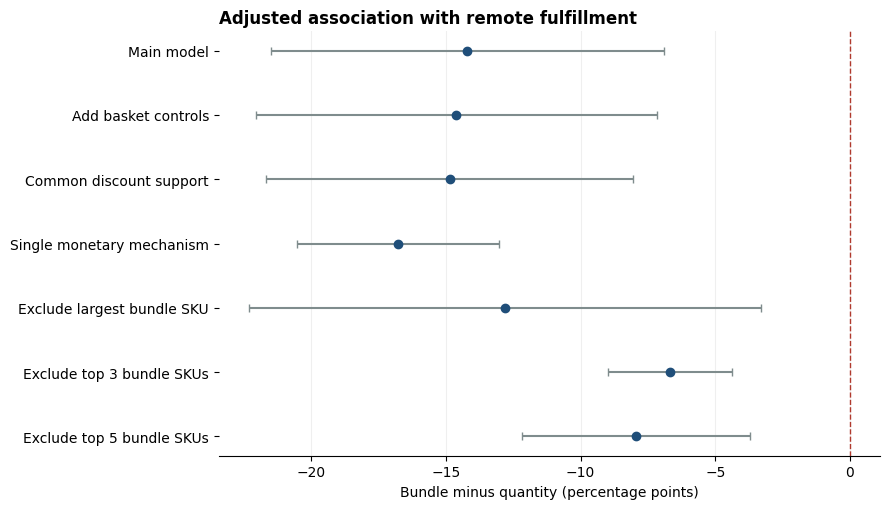

In [10]:
import matplotlib.pyplot as plt

remote_plot = decision_table[
    decision_table["outcome"].eq("remote_any")
    & decision_table["model_family"].isin(FAMILY_ORDER[:7])
].copy()
remote_plot = remote_plot.sort_values("specification_order")

y = np.arange(len(remote_plot))
estimate = remote_plot["reported_estimate"].to_numpy()
lower_error = (
    estimate - remote_plot["reported_ci_low"].to_numpy()
)
upper_error = (
    remote_plot["reported_ci_high"].to_numpy() - estimate
)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.errorbar(
    estimate,
    y,
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    color="#1f4e79",
    ecolor="#7f8c8d",
    capsize=3,
    markersize=6,
)
ax.axvline(0, color="#b03a2e", linewidth=1, linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(remote_plot["specification"])
ax.invert_yaxis()
ax.set_xlabel(
    "Bundle minus quantity (percentage points)"
)
ax.set_title(
    "Adjusted association with remote fulfillment",
    loc="left",
    weight="bold",
)
ax.grid(axis="x", alpha=0.2)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()

figure_path = FIGURE_DIR / "remote_fulfillment_robustness.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved figure: {figure_path.relative_to(ROOT)}")

## 11. Interpretation and limits

The main remote-fulfillment estimate is about −14.2 percentage points. It remains negative after removing the most common bundle products, although the magnitude changes. The five largest bundle products account for about 90% of bundle orders, so this stability check is central to the interpretation.

Only 18 primary SKUs meet strict overlap. The main comparison therefore adjusts for coarser brand/attribute groups and can retain product selection bias. Delivery results change sign under concentration exclusions and do not support a stable delivery-speed advantage. Missing warehouse information and the inventory-listing proxy further limit measurement.

These are associations among observed orders, not effects of assigning a promotion. Discount and basket controls may themselves be related to promotion choice. A causal study would need stronger assignment information or a credible experimental/quasi-experimental design.

## 12. Save run settings

CSV tables are saved in `results/`; the selected figure is saved in `figures/`.

In [11]:
concentration_at = {
    k: float(
        bundle_sku_concentration.loc[
            bundle_sku_concentration["bundle_rank"].eq(k),
            "cumulative_bundle_share",
        ].iloc[0]
    )
    for k in [1, 3, 5]
}

run_log = pd.DataFrame(
    {
        "setting": [
            "data_dir",
            "inventory_check_previous_day",
            "max_model_rows",
            "model_fixed_effects",
            "cluster_variable",
            "strict_overlap_skus_found",
            "strict_overlap_threshold",
            "top_1_bundle_share",
            "top_3_bundle_share",
            "top_5_bundle_share",
            "fe_tolerance",
            "fe_max_iterations",
            "random_seed",
        ],
        "value": [
            "data/raw",
            INVENTORY_CHECK_PREVIOUS_DAY,
            MAX_MODEL_ROWS,
            ", ".join(MODEL_FE),
            "primary_sku",
            len(strict_overlap_skus),
            MIN_STRICT_OVERLAP_SKUS,
            concentration_at[1],
            concentration_at[3],
            concentration_at[5],
            FE_TOL,
            FE_MAX_ITER,
            RANDOM_SEED,
        ],
    }
)
record_table("99_run_log", run_log)

,setting,value
0,data_dir,data/raw
1,inventory_check_previous_day,True
2,max_model_rows,None
3,model_fixed_effects,"brand_attribute_cell, order_date_str, order_ho..."
4,cluster_variable,primary_sku
5,strict_overlap_skus_found,18
6,strict_overlap_threshold,20
7,top_1_bundle_share,0.4541
8,top_3_bundle_share,0.7425
9,top_5_bundle_share,0.9003
